### Part 1: Calculate Win-Rate Ranking using between_cats

%pip install pandas

In [1]:
from pathlib import Path
import pandas as pd

# Return to the project root directory from "交接2", then enter "交接1" to read data
data_path = Path("../交接1/data/processed/train_clean.csv")

# The cat's identification number is read from text to avoid it being automatically converted to a number.
df = pd.read_csv(
    data_path,
    dtype={"a_cat": str, "b_cat": str,
           "winner_cat": str, "loser_cat": str}
)

# Part Two only analyzes comparisons between different cats
between = df.loc[df["comparison_type"] == "between_cats"].copy()

print("Total number of records in the training set:", len(df))
print("Comparison numbers between different cats:", len(between))
print("Number of cats involved:",
      pd.concat([between["a_cat"], between["b_cat"]]).nunique())

# View the first 5 records
between[
    ["a_cat", "b_cat", "choice", "winner_cat", "loser_cat"]
].head()

Total number of records in the training set: 24896
Comparison numbers between different cats: 21893
Number of cats involved: 237


,a_cat,b_cat,choice,winner_cat,loser_cat
1,cat_000751,cat_005017,A,cat_000751,cat_005017
3,cat_000406,cat_001177,A,cat_000406,cat_001177
4,cat_000361,cat_000360,B,cat_000360,cat_000361
6,cat_001672,cat_002143,A,cat_001672,cat_002143
8,cat_003852,cat_000005,B,cat_000005,cat_003852


In [2]:
# Count the number of times each cat wins and loses
wins = between["winner_cat"].value_counts().rename("wins")
losses = between["loser_cat"].value_counts().rename("losses")

# Merge by cat number; enter 0 if there are no wins or losses
ranking = pd.concat([wins, losses], axis=1).fillna(0).astype(int)
ranking.index.name = "cat_id"
ranking = ranking.reset_index()

# Calculate the number of comparisons and the win rate
ranking["comparisons"] = ranking["wins"] + ranking["losses"]
ranking["win_rate"] = ranking["wins"] / ranking["comparisons"]

# Ranked by win rate, those with the same win rate are tied
ranking["win_rate_rank"] = (
    ranking["win_rate"].rank(method="min", ascending=False).astype(int)
)

ranking = ranking.sort_values(
    ["win_rate", "cat_id"],
    ascending=[False, True]
).reset_index(drop=True)

ranking = ranking[
    ["win_rate_rank", "cat_id", "comparisons", "wins", "losses", "win_rate"]
]

# Verification and statistics: Each comparison yields exactly one win and one loss
assert ranking["wins"].sum() == len(between)
assert ranking["losses"].sum() == len(between)
assert ranking["comparisons"].sum() == 2 * len(between)

print("The 10 cats with the highest win rate:")
ranking.head(10)

The 10 cats with the highest win rate:


,win_rate_rank,cat_id,comparisons,wins,losses,win_rate
0,1,cat_000024,201,150,51,0.746269
1,2,cat_001013,175,130,45,0.742857
2,3,cat_000013,195,141,54,0.723077
3,4,cat_000406,213,153,60,0.718310
4,5,cat_000015,170,119,51,0.700000
5,6,cat_000005,191,133,58,0.696335
6,7,cat_000010,186,127,59,0.682796
7,8,cat_000028,185,126,59,0.681081
8,9,cat_000018,194,131,63,0.675258
9,10,cat_001697,203,133,70,0.655172


In [3]:
# Create a results directory in the current "交接2" folder.
output_dir = Path("outputs/tables")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the rankings of all 237 cats, not just the top 10
ranking.to_csv(
    output_dir / "cat_win_rate_ranking.csv",
    index=False,
    encoding="utf-8-sig"
)

print("The complete rankings have been saved to:")
print((output_dir / "cat_win_rate_ranking.csv").resolve())

print("\nThe 10 cats with the lowest win rates (starting from the lowest):")
ranking.sort_values(
    ["win_rate", "cat_id"],
    ascending=[True, True]
).head(10)

The complete rankings have been saved to:
/Users/heart/Desktop/Master/statistical-data-mining5101-/交接2/outputs/tables/cat_win_rate_ranking.csv

The 10 cats with the lowest win rates (starting from the lowest):


,win_rate_rank,cat_id,comparisons,wins,losses,win_rate
236,237,cat_003674,167,40,127,0.239521
235,236,cat_002229,189,47,142,0.248677
234,235,cat_000145,185,50,135,0.270270
233,234,cat_002627,165,46,119,0.278788
232,233,cat_001122,185,54,131,0.291892
231,232,cat_000486,168,51,117,0.303571
230,231,cat_000911,196,62,134,0.316327
229,230,cat_001574,193,62,131,0.321244
228,229,cat_003758,189,61,128,0.322751
227,228,cat_002956,177,58,119,0.327684


### Part 2: Build Bradley Terry Model and Ranking Comparison

%pip install scipy

In [4]:
import numpy as np
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

# Create a numerical index for each cat to facilitate subsequent calculations
cats = sorted(set(between["a_cat"]) | set(between["b_cat"]))
cat_to_idx = {cat: i for i, cat in enumerate(cats)}

winner_idx = between["winner_cat"].map(cat_to_idx).to_numpy()
loser_idx = between["loser_cat"].map(cat_to_idx).to_numpy()
n_cats = len(cats)

# Establish a directional win-loss network: Winning cat to Losing cat
win_graph = coo_matrix(
    (np.ones(len(between)), (winner_idx, loser_idx)),
    shape=(n_cats, n_cats)
).tocsr()

n_components, _ = connected_components(
    win_graph,
    directed=True,
    connection="strong"
)

print("Number of cats:", n_cats)
print("Number of strongly connected components in a win-lose network:", n_components)

if n_components == 1:
    print("The check passed: After fixing the score baseline, a unique and finite general BT model can be estimated")
else:
    print("Further processing is needed: the ordinary BT model may not have a finite solution, so do not directly fit it")

Number of cats: 237
Number of strongly connected components in a win-lose network: 1
The check passed: After fixing the score baseline, a unique and finite general BT model can be estimated


In [5]:
from scipy.optimize import minimize
from scipy.special import expit

# Negative log-likelihood and its gradient; fixing the score of the first cat as 0
def bt_objective(free_scores):
    scores = np.concatenate(([0.0], free_scores))

    # In each record: Winning cat score - Losing cat score
    difference = scores[winner_idx] - scores[loser_idx]

    # The smaller the mean negative log-likelihood, the better the model matches the observed wins and losses
    loss = np.logaddexp(0, -difference).mean()

    # Gradient: tells the optimizer how to adjust the scores of each cat
    q = expit(-difference)
    gradient = (
        np.bincount(loser_idx, weights=q, minlength=n_cats)
        - np.bincount(winner_idx, weights=q, minlength=n_cats)
    ) / len(between)

    return loss, gradient[1:]


# Fitting an unregularized ordinary BT model
result = minimize(
    bt_objective,
    x0=np.zeros(n_cats - 1),
    jac=True,
    method="L-BFGS-B",
    options={"maxiter": 5000, "gtol": 1e-8, "ftol": 1e-12}
)

print("Whether it converges:", result.success)
print("Optimizer Description:", result.message)
print("The final maximum absolute value of the gradient:", np.max(np.abs(result.jac)))

if not result.success:
    raise RuntimeError("The optimization has not yet been successful. Please check the results first and do not use the ranking directly")

# Center the scores so that the average score of all cats is 0
bt_scores = np.concatenate(([0.0], result.x))
bt_scores = bt_scores - bt_scores.mean()

# Generate BT rankings and merge them with previous win rate statistics
bt_table = pd.DataFrame({
    "cat_id": cats,
    "bt_score": bt_scores
})

bt_table["bt_rank"] = (
    bt_table["bt_score"]
    .rank(method="min", ascending=False)
    .astype(int)
)

comparison = ranking.merge(
    bt_table,
    on="cat_id",
    validate="one_to_one"
)

comparison = comparison.sort_values(
    ["bt_rank", "cat_id"]
).reset_index(drop=True)

print("\nBT Top 10: ")
comparison[
    ["bt_rank", "cat_id", "bt_score",
     "win_rate_rank", "win_rate", "comparisons"]
].head(10)

Whether it converges: True
Optimizer Description: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
The final maximum absolute value of the gradient: 9.019805567842634e-09

BT Top 10: 


,bt_rank,cat_id,bt_score,win_rate_rank,win_rate,comparisons
0,1,cat_000024,1.430274,1,0.746269,201
1,2,cat_001013,1.352065,2,0.742857,175
2,3,cat_000013,1.244340,3,0.723077,195
3,4,cat_000406,1.223371,4,0.718310,213
4,5,cat_000005,1.108862,6,0.696335,191
5,6,cat_000015,1.100084,5,0.700000,170
6,7,cat_000018,1.061705,9,0.675258,194
7,8,cat_000028,0.982374,8,0.681081,185
8,9,cat_001697,0.973376,10,0.655172,203
9,10,cat_000010,0.964477,7,0.682796,186


In [6]:
from scipy.stats import spearmanr
from IPython.display import display

# A positive number indicates an increase in BT ranking.
comparison["rank_change"] = (
    comparison["win_rate_rank"] - comparison["bt_rank"]
)

# Measuring the overall consistency of the rankings between the two methods
rho, _ = spearmanr(
    comparison["win_rate"],
    comparison["bt_score"]
)

print(f"Spearman correlation coefficient between the two rankings: {rho:.4f}")

# Compare the top 10 lists
win_top10 = set(ranking.head(10)["cat_id"])
bt_top10 = set(comparison.head(10)["cat_id"])
print(f"Number of overlaps in the top 10: {len(win_top10 & bt_top10)}/10")

# Save all cat model scores and ranking comparisons
comparison.to_csv(
    output_dir / "cat_ranking_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

# Showing the 10 cats with the biggest changes in ranking
largest_changes = (
    comparison.assign(
        absolute_change=comparison["rank_change"].abs()
    )
    .sort_values(
        ["absolute_change", "cat_id"],
        ascending=[False, True]
    )
    .head(10)
)

print("\nThe 10 cats with the biggest changes in ranking:")
display(largest_changes[
    ["cat_id", "win_rate_rank", "bt_rank", "rank_change",
     "win_rate", "bt_score", "comparisons"]
])

print("\nThe 10 lowest-ranked cats on BitTorrent:")
display(comparison.sort_values("bt_rank", ascending=False).head(10)[
    ["bt_rank", "cat_id", "bt_score", "win_rate_rank",
     "win_rate", "comparisons"]
])

Spearman correlation coefficient between the two rankings: 0.9730
Number of overlaps in the top 10: 10/10

The 10 cats with the biggest changes in ranking:


,cat_id,win_rate_rank,bt_rank,rank_change,win_rate,bt_score,comparisons
88,cat_005010,149,89,60,0.469136,0.234615,162
174,cat_001761,126,175,-49,0.497175,-0.380930,177
39,cat_000996,87,40,47,0.541667,0.531351,192
173,cat_005012,127,174,-47,0.496644,-0.362230,149
191,cat_000169,148,192,-44,0.470930,-0.516339,172
55,cat_004182,100,56,44,0.530928,0.411387,194
150,cat_000361,191,151,40,0.411765,-0.174063,187
117,cat_000491,158,118,40,0.457895,0.061397,190
112,cat_003826,153,113,40,0.463768,0.082303,207
97,cat_001922,60,98,-38,0.560976,0.189058,164



The 10 lowest-ranked cats on BitTorrent:


,bt_rank,cat_id,bt_score,win_rate_rank,win_rate,comparisons
236,237,cat_003674,-1.480895,237,0.239521,167
235,236,cat_002229,-1.408757,236,0.248677,189
234,235,cat_000145,-1.370530,235,0.270270,185
233,234,cat_000486,-1.204155,232,0.303571,168
232,233,cat_000911,-1.161324,231,0.316327,196
231,232,cat_001122,-1.150740,233,0.291892,185
230,231,cat_002956,-1.130640,228,0.327684,177
229,230,cat_001574,-1.099403,230,0.321244,193
228,229,cat_003758,-1.028457,229,0.322751,189
227,228,cat_002627,-0.995533,234,0.278788,165


### Part 3: Visualization of Ranking Results

%pip install matplotlib

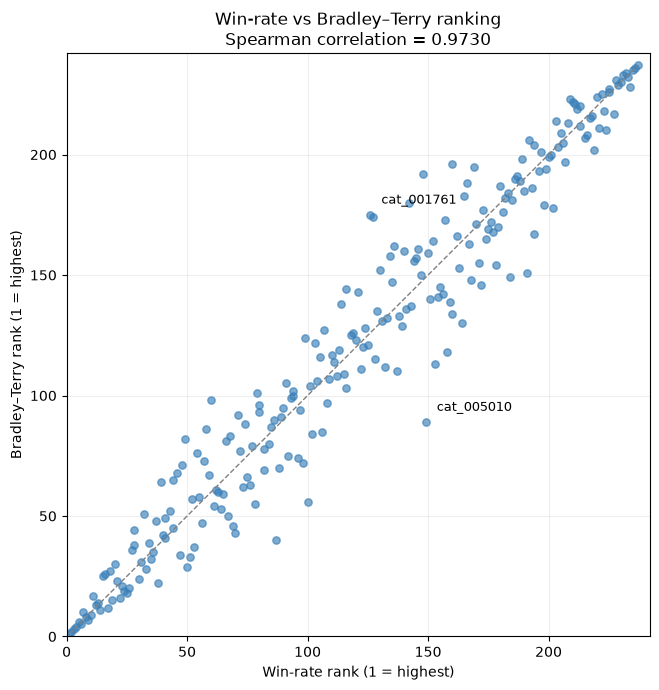

In [7]:
import matplotlib.pyplot as plt

# Save the image to "交接2"/outputs/figures
figure_dir = Path("outputs/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(7, 7))

# Each dot represents a cat
ax.scatter(
    comparison["win_rate_rank"],
    comparison["bt_rank"],
    color="#377EB8",
    alpha=0.65,
    s=28
)

# Dashed lines indicate that the two rankings are exactly the same
ax.plot(
    [1, n_cats], [1, n_cats],
    linestyle="--", color="gray", linewidth=1
)

# Mark the two cats with the biggest changes in ranking
for _, row in largest_changes.head(2).iterrows():
    ax.annotate(
        row["cat_id"],
        (row["win_rate_rank"], row["bt_rank"]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=9
    )

ax.set(
    xlabel="Win-rate rank (1 = highest)",
    ylabel="Bradley–Terry rank (1 = highest)",
    title=f"Win-rate vs Bradley–Terry ranking\nSpearman correlation = {rho:.4f}",
    xlim=(0, n_cats + 5),
    ylim=(0, n_cats + 5)
)

ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
fig.tight_layout()

fig.savefig(
    figure_dir / "01_rank_comparison.png",
    dpi=300, bbox_inches="tight"
)
fig.savefig(
    figure_dir / "01_rank_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

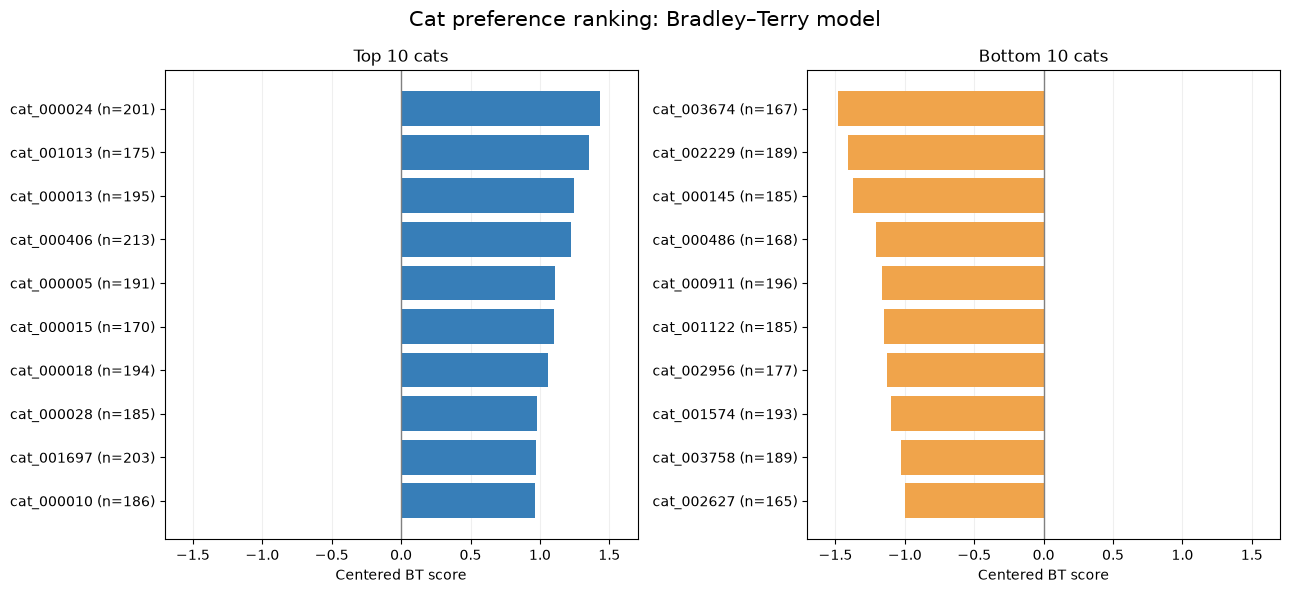

In [8]:
# Select the top 10 and bottom 10 cats based on their BT scores
top10 = comparison.nlargest(10, "bt_score")
bottom10 = comparison.nsmallest(10, "bt_score")

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, data, title, color in [
    (axes[0], top10, "Top 10 cats", "#377EB8"),
    (axes[1], bottom10, "Bottom 10 cats", "#F0A44B")
]:
    # The tag displays both the cat's ID number and the number of comparisons.
    labels = [
        f"{row.cat_id} (n={row.comparisons})"
        for row in data.itertuples()
    ]

    ax.barh(labels, data["bt_score"], color=color)
    ax.invert_yaxis()
    ax.axvline(0, color="gray", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("Centered BT score")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

# The two images use the same scale for easy comparison
limit = comparison["bt_score"].abs().max() * 1.15
for ax in axes:
    ax.set_xlim(-limit, limit)

fig.suptitle(
    "Cat preference ranking: Bradley–Terry model",
    fontsize=15
)
fig.tight_layout()

fig.savefig(
    figure_dir / "02_bt_top_bottom.png",
    dpi=300, bbox_inches="tight"
)
fig.savefig(
    figure_dir / "02_bt_top_bottom.pdf",
    bbox_inches="tight"
)

plt.show()

### Part 3: Environment and Dependencies

In [9]:
import platform
from importlib.metadata import version

# Record the dependency versions actually used in this analysis
packages = ["numpy", "pandas", "scipy", "matplotlib"]
requirements = "\n".join(
    f"{package}=={version(package)}"
    for package in packages
) + "\n"

Path("requirements.txt").write_text(requirements, encoding="utf-8")

environment = (
    f"Python: {platform.python_version()}\n"
    f"Platform: {platform.platform()}\n"
)

Path("environment.txt").write_text(environment, encoding="utf-8")

print(environment)
print(requirements)
print("requirements.txt and environment.txt have been saved.")

Python: 3.14.7
Platform: macOS-26.6-arm64-arm-64bit-Mach-O

numpy==2.5.3
pandas==3.1.0
scipy==1.18.1
matplotlib==3.11.2

requirements.txt and environment.txt have been saved.
